# Endometriosis Pain: Gene Expression and Pathway Analysis

**Independent secondary analysis of published summary results**  
**Source:** Mamillapalli et al. (2026), [GEO GSE339400](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE339400)

## 1. Introduction and research question

How do reported gene-expression patterns and biological functions differ between symptomatic and asymptomatic endometriosis samples, and which published gene co-expression modules correlate with pain?

This notebook explores published differential-expression, gene set enrichment (GSEA), and WGCNA summary tables. **The original study authors generated the RNA-seq differential-expression, GSEA, and WGCNA results.** My independent work consists of data inspection, filtering, visualizations, and Benjamini–Hochberg correction of the 40 published module–pain p-values.

**Tools:** Python, pandas, NumPy, Matplotlib, statsmodels, openpyxl.

## 2. Study population and dataset

The study reports **27 tissue samples from 19 patients**: 13 samples from 10 asymptomatic patients and 14 samples from 9 symptomatic patients. Some patients contributed multiple samples. Group characteristics and sequencing metrics are described in the published Table 1.

**Limitations to keep in mind:** small patient cohort; potentially non-independent tissue samples; age and hormonal-status differences; and use of published summary statistics rather than raw sequencing reads.

## 3. Data loading and quality checks


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from urllib.request import urlretrieve
from statsmodels.stats.multitest import multipletests

# Public GEO supplementary dataset
data_url = (
    "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE339nnn/"
    "GSE339400/suppl/"
    "GSE339400%5FEndo%5FRNAseq%5Fmanuscript%5Ftables%2Exlsx"
)

# Store the workbook in the notebook environment
data_dir = Path("data")
data_dir.mkdir(exist_ok=True)

file_path = data_dir / "GSE339400_Endo_RNAseq_manuscript_tables.xlsx"

# Download only if the file is not already available
if not file_path.exists():
    urlretrieve(data_url, file_path)

print("Dataset ready:", file_path)

# Confirm that the workbook loads successfully
excel_file = pd.ExcelFile(file_path)
print("Available worksheets:", excel_file.sheet_names)

Dataset ready: data/GSE339400_Endo_RNAseq_manuscript_tables.xlsx
Available worksheets: ['Table 1 - Patient charcteristic', 'Table 2 - Top 15 upregulated ge', 'Table 3 - Top 15 downregulated ', 'Table 4 - Top GSEA Results', 'Table 5 - WGCNA modules', 'Table 6 - Module GSEA analysis', 'Supp Table 1 - Full DE results', 'Supp Table 2 - Full GSEA Result']


In [2]:
# Load the full differential gene expression results
df = pd.read_excel(
    file_path,
    sheet_name="Supp Table 1 - Full DE results"
)

# Check that the data loaded correctly
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (19836, 8)


,GeneName,mean_Sx,mean_Asx,log2FoldChange,lfcSE,stat,pvalue,padj
0,OLFML1,1294.351027,477.793879,1.437668,0.226880,6.336696,2.347438e-10,0.000001
1,POLR2J2,243.105788,5.708346,5.410322,0.843884,6.411214,1.443657e-10,0.000001
2,SLC7A5,181.398953,1326.749768,-2.871404,0.481301,-5.965925,2.432517e-09,0.000009
3,MT-ND6,1224.952926,3663.117166,-1.579969,0.268108,-5.893024,3.791905e-09,0.000011
4,AOX1,3111.287217,1119.585906,1.474334,0.261345,5.641330,1.687416e-08,0.000039


In [3]:

# How many rows and columns?
print("Dataset shape:", df.shape)

# See the column names
print("\nColumns:")
print(df.columns.tolist())

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Get summary statistics
df.describe()


Dataset shape: (19836, 8)

Columns:
['GeneName', 'mean_Sx', 'mean_Asx', 'log2FoldChange', 'lfcSE', 'stat', 'pvalue', 'padj']

Missing values:
GeneName             0
mean_Sx              0
mean_Asx             0
log2FoldChange    1609
lfcSE             1609
stat              1609
pvalue            1609
padj              8393
dtype: int64


,mean_Sx,mean_Asx,log2FoldChange,lfcSE,stat,pvalue,padj
count,19836.000000,19836.000000,18227.000000,18227.000000,18227.000000,1.822700e+04,11443.000000
mean,719.965004,782.690052,-0.355325,0.744377,-0.278825,3.992107e-01,0.513454
std,2701.034461,3540.018772,1.113421,0.851157,1.454776,3.169630e-01,0.314161
min,0.000000,0.000000,-7.869127,0.000000,-6.803687,1.588120e-30,0.000001
25%,10.754326,16.257077,-0.627892,0.212682,-1.198023,9.607673e-02,0.221506
50%,183.077506,200.376134,-0.138984,0.367242,-0.337508,3.506655e-01,0.538044
75%,666.896902,692.292706,0.182340,0.840667,0.540664,6.710441e-01,0.803290
max,167755.004631,255974.148689,24.738421,2.992367,11.483973,1.000000e+00,0.999884


### Patient characteristics (published Table 1)

These are descriptive study characteristics, not new patient-level statistical tests.

In [4]:

patient_df = pd.read_excel(
    file_path,
    sheet_name="Table 1 - Patient charcteristic",
    header=None
)

print("Shape:", patient_df.shape)

with pd.option_context(
    "display.max_rows", 100,
    "display.max_columns", None,
    "display.max_colwidth", 100
):
    display(patient_df)


Shape: (9, 3)


,0,1,2
0,NaN,Asymptomatic,Symptomatic
1,Number of samples,13,14
2,Number of unique patients,10,9
3,Age at surgery (yrs),38.3 ± 6.5,34.2 ± 4.2
4,Race,White 7; Latina 2; Black 1,White 6; Latina 2; Black 1
5,Hormonal status,"Nuvaring (1), OCPs (1), 5w pregnant (1)",OCPs (2)
6,Specimen age (months),40.0 ± 6.2,40.5 ± 7.8
7,Overall alignment (%),89.4 ± 6.0,92.7 ± 2.0
8,Mean insert size (nt),164.2 ± 16.2,182.1 ± 11.6


## 4. Differential gene expression

The original authors estimated log2 fold changes and adjusted p-values. Here, positive log2 fold change is interpreted as higher expression in symptomatic relative to asymptomatic samples, subject to the study's contrast definition.

Two thresholds are reported separately: **adjusted p < 0.05** (statistical significance), and **adjusted p < 0.05 with |log2FC| > 1** (the stricter filter used for highlighting genes in the volcano plot). Genes with missing adjusted p-values cannot be classified as significant using this criterion.

In [5]:

# Count missing adjusted p-values
print("Total genes:", len(df))

print("Missing adjusted p-values:",
      df["padj"].isna().sum())

print("Valid adjusted p-values:",
      df["padj"].notna().sum())

# Compare genes with and without adjusted p-values
df.groupby(df["padj"].isna())["log2FoldChange"].describe()


Total genes: 19836
Missing adjusted p-values: 8393
Valid adjusted p-values: 11443


,count,mean,std,min,25%,50%,75%,max
padj,,,,,,,,
False,11443.0,-0.085180,0.503669,-5.588195,-0.342287,-0.049915,0.204775,5.410322
True,6784.0,-0.810996,1.603868,-7.869127,-1.485974,-0.576474,0.086389,24.738421


In [6]:
print("Genes with adjusted p < 0.05:", (df["padj"] < 0.05).sum())
print("Genes with adjusted p < 0.05 and |log2FC| > 1:", ((df["padj"] < 0.05) & (df["log2FoldChange"].abs() > 1)).sum())

Genes with adjusted p < 0.05: 890
Genes with adjusted p < 0.05 and |log2FC| > 1: 262


In [7]:

# Define our significance criteria
alpha = 0.05
min_log2fc = 1

# Select genes that meet both criteria
significant = df[
    (df["padj"] < alpha) &
    (df["log2FoldChange"].abs() > min_log2fc)
].copy()

# Split into higher and lower expression
upregulated = significant[
    significant["log2FoldChange"] > 0
]

downregulated = significant[
    significant["log2FoldChange"] < 0
]

print("Total genes:", len(df))
print("Significant genes:", len(significant))
print("Upregulated genes:", len(upregulated))
print("Downregulated genes:", len(downregulated))


Total genes: 19836
Significant genes: 262
Upregulated genes: 73
Downregulated genes: 189


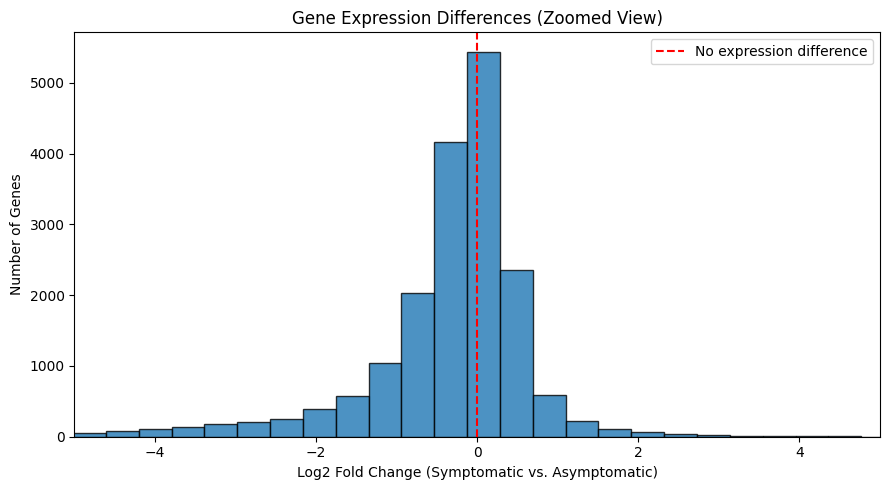

In [8]:
# Exclude missing fold changes before plotting
fold_changes = df["log2FoldChange"].dropna()


plt.figure(figsize=(9, 5))

plt.hist(
    fold_changes,
    bins=80,
    edgecolor="black",
    alpha=0.8
)

plt.xlim(-5, 5)

plt.axvline(0, color="red", linestyle="--",
            label="No expression difference")

plt.xlabel("Log2 Fold Change (Symptomatic vs. Asymptomatic)")
plt.ylabel("Number of Genes")
plt.title("Gene Expression Differences (Zoomed View)")

plt.legend()
plt.tight_layout()
plt.show()


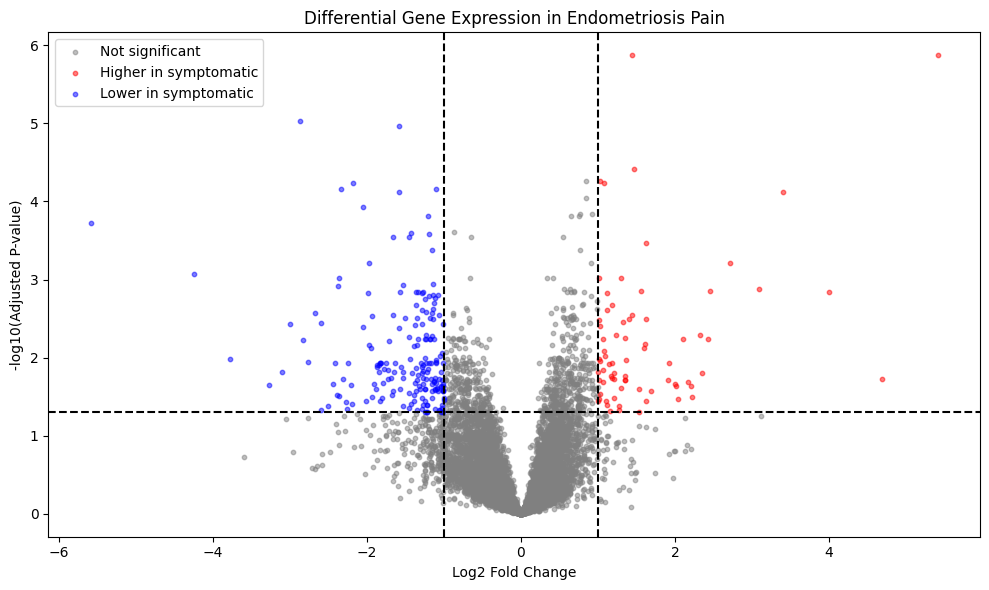

In [9]:

import numpy as np
import matplotlib.pyplot as plt

# Keep genes with valid values for plotting
volcano = df.dropna(
    subset=["log2FoldChange", "padj"]
).copy()

# Adjusted p-values must be greater than zero
volcano = volcano[volcano["padj"] > 0].copy()

# Calculate statistical significance
volcano["neg_log10_padj"] = -np.log10(volcano["padj"])

# Classify genes
volcano["category"] = "Not significant"

volcano.loc[
    (volcano["padj"] < 0.05) &
    (volcano["log2FoldChange"] > 1),
    "category"
] = "Higher in symptomatic"

volcano.loc[
    (volcano["padj"] < 0.05) &
    (volcano["log2FoldChange"] < -1),
    "category"
] = "Lower in symptomatic"

colors = {
    "Not significant": "gray",
    "Higher in symptomatic": "red",
    "Lower in symptomatic": "blue"
}

plt.figure(figsize=(10, 6))

for category, color in colors.items():
    subset = volcano[volcano["category"] == category]

    plt.scatter(
        subset["log2FoldChange"],
        subset["neg_log10_padj"],
        c=color,
        label=category,
        alpha=0.5,
        s=10
    )

plt.axhline(
    -np.log10(0.05),
    color="black",
    linestyle="--"
)

plt.axvline(-1, color="black", linestyle="--")
plt.axvline(1, color="black", linestyle="--")

plt.xlabel("Log2 Fold Change")
plt.ylabel("-log10(Adjusted P-value)")
plt.title("Differential Gene Expression in Endometriosis Pain")

plt.legend()
plt.tight_layout()
plt.savefig("endometriosis_volcano_plot.png",
            dpi=300, bbox_inches="tight")
plt.show()


### Selected inflammation-associated genes

These genes were highlighted in the original publication. The comparison below is **not** a new differential-expression test.

In [10]:

# Genes discussed in the study's inflammatory findings
inflammatory_genes = [
    "IL16",
    "IL17RA",
    "JAK3",
    "SMPD3",
    "RELT"
]

# Extract their differential expression results
inflammation_df = df[
    df["GeneName"].isin(inflammatory_genes)
].copy()

# Sort by adjusted p-value
inflammation_df = inflammation_df.sort_values("padj")

# Display results
inflammation_df[
    ["GeneName", "log2FoldChange", "pvalue", "padj"]
]


,GeneName,log2FoldChange,pvalue,padj
5,IL16,1.026167,3.306315e-08,0.000054
10,RELT,-2.341190,6.664293e-08,0.000069
22,IL17RA,-1.428911,5.090865e-07,0.000253
30,JAK3,-1.154837,1.127113e-06,0.000416
49,SMPD3,2.453306,6.167938e-06,0.001412


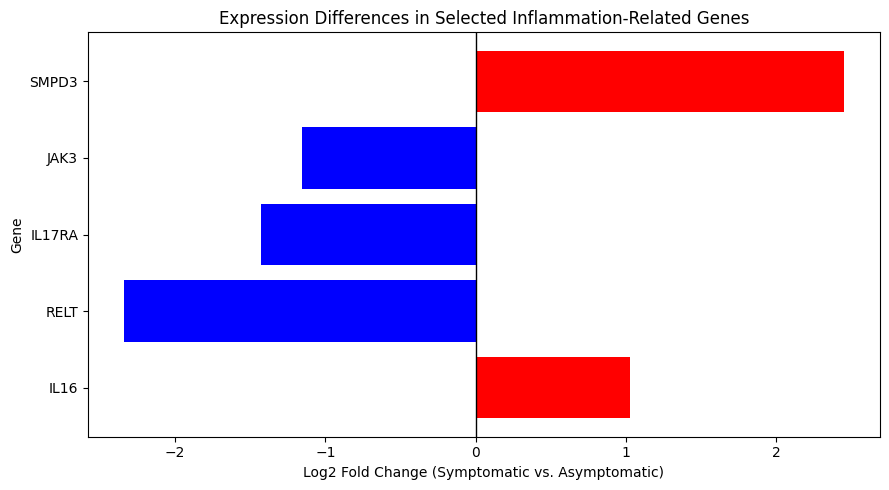

In [11]:

import matplotlib.pyplot as plt

# Choose colors based on direction of expression
colors = [
    "red" if fc > 0 else "blue"
    for fc in inflammation_df["log2FoldChange"]
]

plt.figure(figsize=(9, 5))

plt.barh(
    inflammation_df["GeneName"],
    inflammation_df["log2FoldChange"],
    color=colors
)

plt.axvline(0, color="black", linewidth=1)

plt.xlabel("Log2 Fold Change (Symptomatic vs. Asymptomatic)")
plt.ylabel("Gene")
plt.title("Expression Differences in Selected Inflammation-Related Genes")

plt.tight_layout()
plt.show()


In [12]:

# Add a column indicating statistical significance
inflammation_df["FDR_significant"] = (
    inflammation_df["padj"] < 0.05
)

inflammation_df[
    ["GeneName", "log2FoldChange", "padj", "FDR_significant"]
]


,GeneName,log2FoldChange,padj,FDR_significant
5,IL16,1.026167,0.000054,True
10,RELT,-2.341190,0.000069,True
22,IL17RA,-1.428911,0.000253,True
30,JAK3,-1.154837,0.000416,True
49,SMPD3,2.453306,0.001412,True


## 5. Gene Set Enrichment Analysis (GSEA)

These are the original authors' published enrichment scores and false-discovery-rate q-values. FDR < 0.05 is treated as the stricter significance threshold; FDR < 0.25 is shown separately as **exploratory**, not confirmatory.

In [13]:

# Load the published pathway enrichment results
gsea_df = pd.read_excel(
    file_path,
    sheet_name="Supp Table 2 - Full GSEA Result"
)

# See the first five rows
display(gsea_df.head())

# Inspect the columns
print("Shape:", gsea_df.shape)
print("Columns:", gsea_df.columns.tolist())

# Check missing values
print("\nMissing values:")
print(gsea_df.isnull().sum())


,NAME,SIZE,ES,NES,NOM p-val,FDR q-val
0,GOMF_HORMONE_ACTIVITY,99,-0.706155,-1.789715,0.0,0.018261
1,GOMF_STRUCTURAL_CONSTITUENT_OF_SKIN_EPIDERMIS,26,-0.781225,-1.757552,0.0,0.027393
2,GOMF_NEUROPEPTIDE_RECEPTOR_BINDING,27,-0.760795,-1.758687,0.0,0.033752
3,GOCC_KERATIN_FILAMENT,58,-0.702864,-1.743280,0.0,0.035052
4,GOBP_POSITIVE_REGULATION_OF_MITOTIC_SISTER_CHR...,17,-0.806569,-1.714700,0.0,0.076575


Shape: (250, 6)
Columns: ['NAME', 'SIZE', 'ES', 'NES', 'NOM p-val', 'FDR q-val']

Missing values:
NAME         0
SIZE         0
ES           0
NES          0
NOM p-val    0
FDR q-val    0
dtype: int64


In [14]:

# Select pathways with FDR below 0.05
significant_pathways = gsea_df[
    gsea_df["FDR q-val"] < 0.05
].copy()

# Sort by FDR q-value
significant_pathways = significant_pathways.sort_values(
    "FDR q-val"
)

print("Total pathways:", len(gsea_df))
print("Significant pathways:", len(significant_pathways))

# Display the top 15
display(significant_pathways.head(15))


Total pathways: 250
Significant pathways: 4


,NAME,SIZE,ES,NES,NOM p-val,FDR q-val
0,GOMF_HORMONE_ACTIVITY,99,-0.706155,-1.789715,0.0,0.018261
1,GOMF_STRUCTURAL_CONSTITUENT_OF_SKIN_EPIDERMIS,26,-0.781225,-1.757552,0.0,0.027393
2,GOMF_NEUROPEPTIDE_RECEPTOR_BINDING,27,-0.760795,-1.758687,0.0,0.033752
3,GOCC_KERATIN_FILAMENT,58,-0.702864,-1.743280,0.0,0.035052


In [15]:

# Compare different GSEA significance thresholds
for threshold in [0.01, 0.05, 0.10, 0.25]:
    count = (gsea_df["FDR q-val"] < threshold).sum()

    print(f"FDR < {threshold}: {count} gene sets")


FDR < 0.01: 0 gene sets
FDR < 0.05: 4 gene sets
FDR < 0.1: 5 gene sets
FDR < 0.25: 22 gene sets


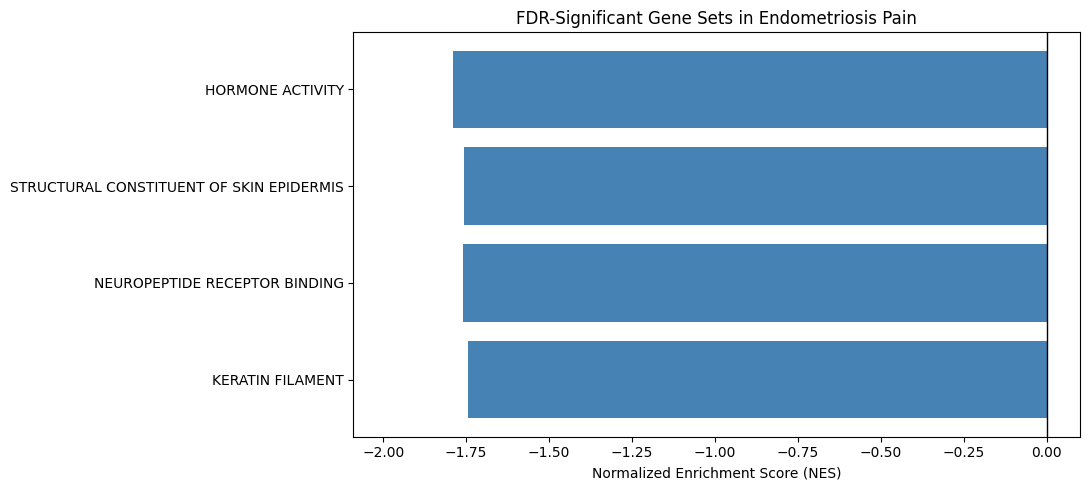

In [16]:

# Plot all four FDR-significant gene sets
plot_df = significant_pathways.copy()

plot_df["CleanName"] = (
    plot_df["NAME"]
    .str.replace(r"^(GOBP_|GOMF_|GOCC_)", "", regex=True)
    .str.replace("_", " ")
)

fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.barh(
    plot_df["CleanName"],
    plot_df["NES"],
    color="steelblue"
)

ax.axvline(0, color="black", linewidth=1)

# Add FDR labels beside each bar
for bar, q in zip(bars, plot_df["FDR q-val"]):
    ax.text(
        bar.get_width() - 0.03,
        bar.get_y() + bar.get_height()/2,
        f"FDR = {q:.3f}",
        va="center",
        ha="right",
        color="white",
        fontsize=10
    )

ax.invert_yaxis()
ax.set_xlim(min(plot_df["NES"]) - 0.3, 0.1)

ax.set_xlabel("Normalized Enrichment Score (NES)")
ax.set_title("FDR-Significant Gene Sets in Endometriosis Pain")

plt.tight_layout()
plt.show()


In [17]:

# Select gene sets using the exploratory GSEA threshold
exploratory_pathways = gsea_df[
    gsea_df["FDR q-val"] < 0.25
].copy()

# Sort by FDR
exploratory_pathways = exploratory_pathways.sort_values(
    "FDR q-val"
)

# Clean names for visualization
exploratory_pathways["CleanName"] = (
    exploratory_pathways["NAME"]
    .str.replace(r"^(GOBP_|GOMF_|GOCC_)", "", regex=True)
    .str.replace("_", " ")
)

display(exploratory_pathways[
    ["CleanName", "NES", "FDR q-val"]
])


,CleanName,NES,FDR q-val
0,HORMONE ACTIVITY,-1.789715,0.018261
1,STRUCTURAL CONSTITUENT OF SKIN EPIDERMIS,-1.757552,0.027393
2,NEUROPEPTIDE RECEPTOR BINDING,-1.758687,0.033752
3,KERATIN FILAMENT,-1.743280,0.035052
4,POSITIVE REGULATION OF MITOTIC SISTER CHROMATI...,-1.714700,0.076575
5,CELLULAR DEFENSE RESPONSE,-1.693605,0.116036
6,POSITIVE REGULATION OF GRANULOCYTE CHEMOTAXIS,-1.668914,0.128431
7,CONNEXIN COMPLEX,-1.671457,0.131476
8,GLUCOCORTICOID METABOLIC PROCESS,-1.663309,0.135114
9,NEUROPEPTIDE SIGNALING PATHWAY,-1.673351,0.137648


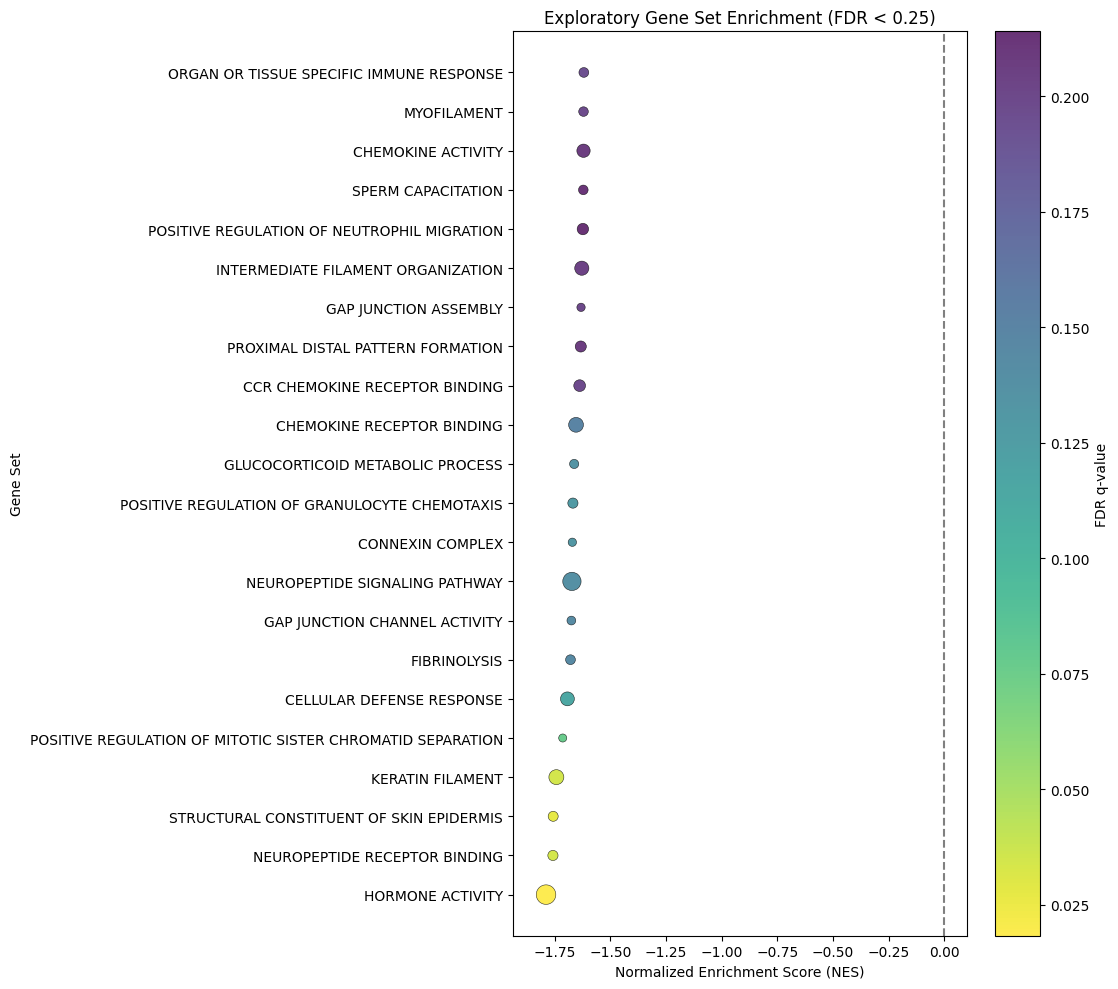

In [18]:

import matplotlib.pyplot as plt
import numpy as np

plot_df = exploratory_pathways.sort_values("NES").copy()

fig, ax = plt.subplots(figsize=(11, 10))

scatter = ax.scatter(
    plot_df["NES"],
    plot_df["CleanName"],
    s=plot_df["SIZE"] * 2,
    c=plot_df["FDR q-val"],
    cmap="viridis_r",
    alpha=0.8,
    edgecolors="black",
    linewidths=0.4
)

ax.axvline(0, color="gray", linestyle="--")

ax.set_xlabel("Normalized Enrichment Score (NES)")
ax.set_ylabel("Gene Set")
ax.set_title("Exploratory Gene Set Enrichment (FDR < 0.25)")

cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("FDR q-value")

ax.set_xlim(min(plot_df["NES"]) - 0.15, max(0, max(plot_df["NES"])) + 0.1)
plt.tight_layout()
plt.show()


## 6. WGCNA module–pain associations

The study reports correlations between 40 co-expression modules and its pain variable. I independently apply the Benjamini–Hochberg (BH) procedure across the **40 published module p-values**. These adjusted values should be interpreted as an additional exploratory correction; verify the original pain-variable coding before assigning biological direction to positive or negative correlations.

In [19]:

# Load the WGCNA module results
wgcna_df = pd.read_excel(
    file_path,
    sheet_name="Table 5 - WGCNA modules"
)

# Display the entire table
display(wgcna_df)

# Check its dimensions and column names
print("Shape:", wgcna_df.shape)
print("Columns:", wgcna_df.columns.tolist())

# Check for missing values
print("\nMissing values:")
print(wgcna_df.isnull().sum())


,module,size,Corr Pain,P-value
0,blue,1659,-0.575025,0.001704
1,cyan,403,-0.554005,0.002715
2,sienna3,107,-0.539047,0.003716
3,red,1000,0.473378,0.012632
4,yellow,1096,-0.468555,0.013697
5,tan,490,-0.458898,0.016054
6,pink,777,0.456603,0.016661
7,darkturquoise,231,0.443507,0.020495
8,lightcyan,364,-0.426045,0.026701
9,darkmagenta,115,-0.394530,0.041701


Shape: (40, 4)
Columns: ['module', 'size', 'Corr Pain', 'P-value']

Missing values:
module       0
size         0
Corr Pain    0
P-value      0
dtype: int64


In [20]:

from statsmodels.stats.multitest import multipletests

# Apply Benjamini-Hochberg correction across 40 modules
wgcna_df["FDR_BH"] = multipletests(
    wgcna_df["P-value"],
    method="fdr_bh"
)[1]

# Add significance indicators
wgcna_df["Nominal_significant"] = (
    wgcna_df["P-value"] < 0.05
)

wgcna_df["FDR_significant"] = (
    wgcna_df["FDR_BH"] < 0.05
)

# Count modules meeting each threshold
print("Total modules:", len(wgcna_df))

print("Nominally significant:",
      wgcna_df["Nominal_significant"].sum())

print("FDR significant:",
      wgcna_df["FDR_significant"].sum())

# Display the strongest associations
display(
    wgcna_df.sort_values("P-value")[
        ["module", "size", "Corr Pain",
         "P-value", "FDR_BH", "FDR_significant"]
    ].head(15)
)


Total modules: 40
Nominally significant: 11
FDR significant: 3


,module,size,Corr Pain,P-value,FDR_BH,FDR_significant
0,blue,1659,-0.575025,0.001704,0.049553,True
1,cyan,403,-0.554005,0.002715,0.049553,True
2,sienna3,107,-0.539047,0.003716,0.049553,True
3,red,1000,0.473378,0.012632,0.095204,False
4,yellow,1096,-0.468555,0.013697,0.095204,False
5,tan,490,-0.458898,0.016054,0.095204,False
6,pink,777,0.456603,0.016661,0.095204,False
7,darkturquoise,231,0.443507,0.020495,0.102475,False
8,lightcyan,364,-0.426045,0.026701,0.118672,False
9,darkmagenta,115,-0.394530,0.041701,0.166805,False


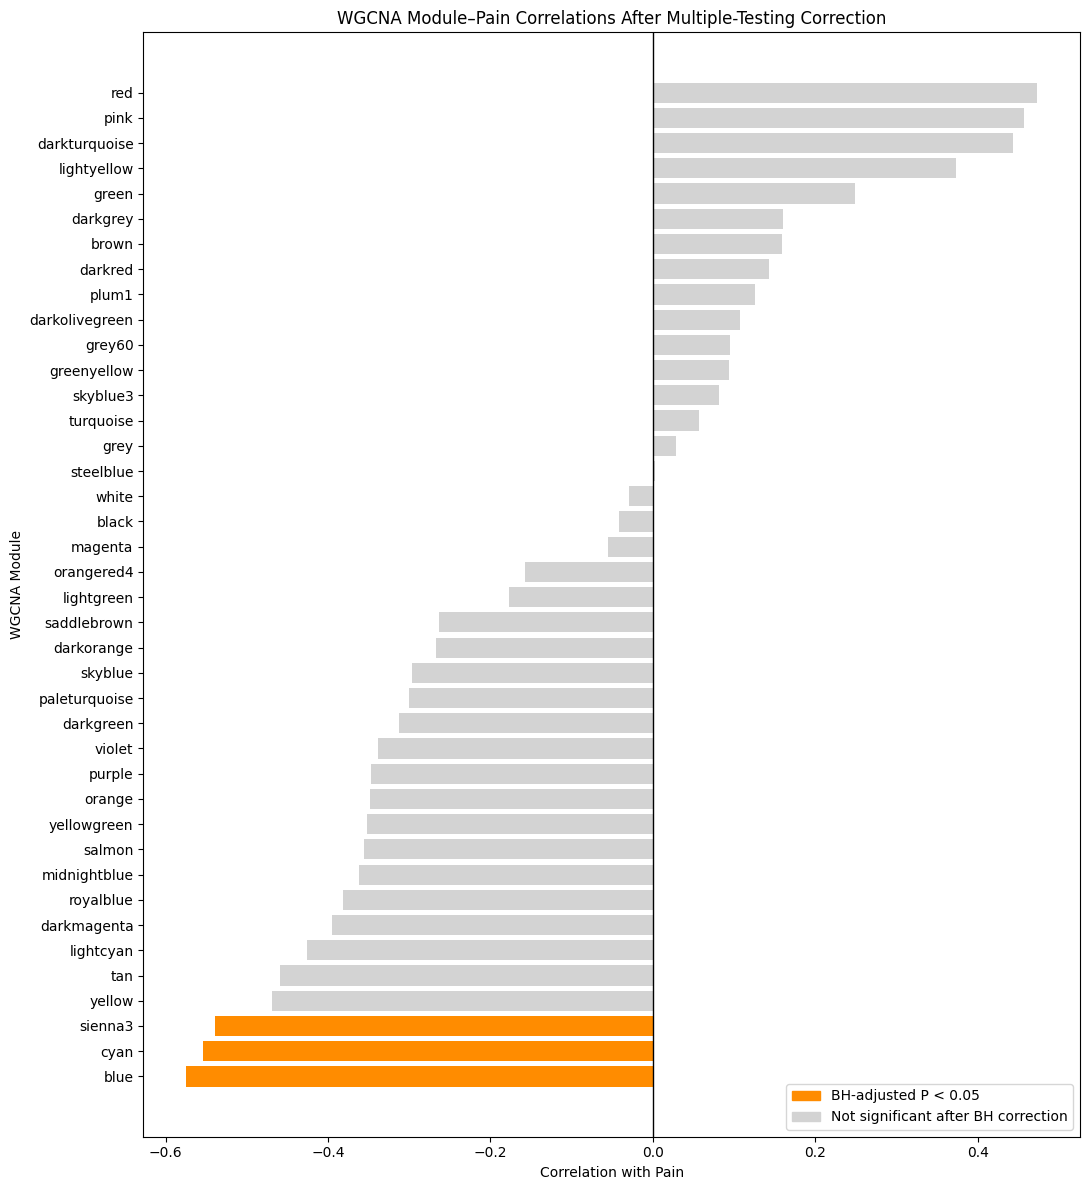

In [21]:

import matplotlib.pyplot as plt

# Sort modules by correlation
plot_df = wgcna_df.sort_values("Corr Pain").copy()

# Highlight modules that pass BH correction
colors = [
    "darkorange" if sig else "lightgray"
    for sig in plot_df["FDR_significant"]
]

fig, ax = plt.subplots(figsize=(11, 12))

ax.barh(
    plot_df["module"],
    plot_df["Corr Pain"],
    color=colors
)

ax.axvline(0, color="black", linewidth=1)

ax.set_xlabel("Correlation with Pain")
ax.set_ylabel("WGCNA Module")
ax.set_title("WGCNA Module–Pain Correlations After Multiple-Testing Correction")


from matplotlib.patches import Patch

ax.legend(
    handles=[
        Patch(color="darkorange", label="BH-adjusted P < 0.05"),
        Patch(color="lightgray", label="Not significant after BH correction")
    ],
    loc="lower right"
)
plt.tight_layout()
plt.show()


### Published module-specific gene set enrichment

Table 6 is organized in separate blocks for blue, cyan, darkmagenta, and red modules. The following cleaning step converts these reported results to a tidy table. **Sienna3 module enrichment is not supplied in this worksheet.** Positive module-level NES values do not by themselves indicate increased pathway activity in symptomatic patients.

In [22]:

# Read every row without treating any row as a header
module_raw = pd.read_excel(
    file_path,
    sheet_name="Table 6 - Module GSEA analysis",
    header=None
)

print("Shape:", module_raw.shape)

# Display all rows and columns
with pd.option_context(
    "display.max_rows", 100,
    "display.max_columns", None,
    "display.max_colwidth", 80
):
    display(module_raw)


Shape: (61, 6)


,0,1,2,3,4,5
0,Blue,NaN,NaN,NaN,NaN,NaN
1,NAME,SIZE,ES,NES,NOM p-val,FDR q-val
2,GOBP_REGULATION_OF_PROTEIN_UBIQUITINATION,18,0.542809,2.322557,0,0.021663
3,GOBP_LYMPHOCYTE_ACTIVATION_INVOLVED_IN_IMMUNE_RESPONSE,21,0.520916,2.342573,0,0.022451
4,GOBP_CELL_CELL_JUNCTION_ORGANIZATION,26,0.508286,2.433743,0,0.023543
5,GOBP_CELLULAR_RESPONSE_TO_MOLECULE_OF_BACTERIAL_ORIGIN,21,0.522271,2.345022,0,0.032619
6,GOBP_CELL_ACTIVATION_INVOLVED_IN_IMMUNE_RESPONSE,32,0.431868,2.231547,0,0.047043
7,GOBP_B_CELL_ACTIVATION,25,0.449337,2.16682,0,0.072206
8,GOBP_CELLULAR_RESPONSE_TO_CARBOHYDRATE_STIMULUS,21,0.481051,2.129486,0,0.078634
9,GOBP_CELLULAR_RESPONSE_TO_BIOTIC_STIMULUS,23,0.458028,2.14125,0.002347,0.078719


In [23]:

import pandas as pd

# Row positions from the worksheet
sections = {
    "blue": (2, 22),
    "cyan": (25, 35),
    "darkmagenta": (38, 52),
    "red": (55, 61)
}

columns = [
    "GeneSet", "Size", "ES",
    "NES", "PValue", "FDR"
]

all_modules = []

for module, (start, end) in sections.items():

    # Extract rows belonging to this module
    section = module_raw.iloc[start:end].copy()

    # Assign consistent column names
    section.columns = columns

    # Add the module identifier
    section["Module"] = module

    all_modules.append(section)

# Combine into one dataset
module_enrichment = pd.concat(
    all_modules,
    ignore_index=True
)

# Convert numeric columns
for col in ["Size", "ES", "NES", "PValue", "FDR"]:
    module_enrichment[col] = pd.to_numeric(
        module_enrichment[col],
        errors="coerce"
    )

# Remove empty rows
module_enrichment = module_enrichment.dropna(
    subset=["GeneSet", "NES", "FDR"]
)

print("Total enrichment results:", len(module_enrichment))

print("\nResults per module:")
print(module_enrichment["Module"].value_counts())

display(module_enrichment.head())


Total enrichment results: 50

Results per module:
Module
blue           20
darkmagenta    14
cyan           10
red             6
Name: count, dtype: int64


,GeneSet,Size,ES,NES,PValue,FDR,Module
0,GOBP_REGULATION_OF_PROTEIN_UBIQUITINATION,18,0.542809,2.322557,0.0,0.021663,blue
1,GOBP_LYMPHOCYTE_ACTIVATION_INVOLVED_IN_IMMUNE_...,21,0.520916,2.342573,0.0,0.022451,blue
2,GOBP_CELL_CELL_JUNCTION_ORGANIZATION,26,0.508286,2.433743,0.0,0.023543,blue
3,GOBP_CELLULAR_RESPONSE_TO_MOLECULE_OF_BACTERIA...,21,0.522271,2.345022,0.0,0.032619,blue
4,GOBP_CELL_ACTIVATION_INVOLVED_IN_IMMUNE_RESPONSE,32,0.431868,2.231547,0.0,0.047043,blue


In [24]:

# Summarize enrichment results by module
summary = module_enrichment.groupby("Module").agg(
    Total_GeneSets=("GeneSet", "count"),
    FDR_005=("FDR", lambda x: (x < 0.05).sum()),
    FDR_025=("FDR", lambda x: (x < 0.25).sum())
)

display(summary)

# Show all gene sets meeting the stricter threshold
significant_sets = module_enrichment[
    module_enrichment["FDR"] < 0.05
].sort_values(["Module", "FDR"])

display(significant_sets[
    ["Module", "GeneSet", "NES", "FDR"]
])


,Total_GeneSets,FDR_005,FDR_025
Module,,,
blue,20,5,20
cyan,10,1,10
darkmagenta,14,0,14
red,6,0,6


,Module,GeneSet,NES,FDR
0,blue,GOBP_REGULATION_OF_PROTEIN_UBIQUITINATION,2.322557,0.021663
1,blue,GOBP_LYMPHOCYTE_ACTIVATION_INVOLVED_IN_IMMUNE_...,2.342573,0.022451
2,blue,GOBP_CELL_CELL_JUNCTION_ORGANIZATION,2.433743,0.023543
3,blue,GOBP_CELLULAR_RESPONSE_TO_MOLECULE_OF_BACTERIA...,2.345022,0.032619
4,blue,GOBP_CELL_ACTIVATION_INVOLVED_IN_IMMUNE_RESPONSE,2.231547,0.047043
20,cyan,GOBP_RNA_SPLICING,2.213826,0.045592


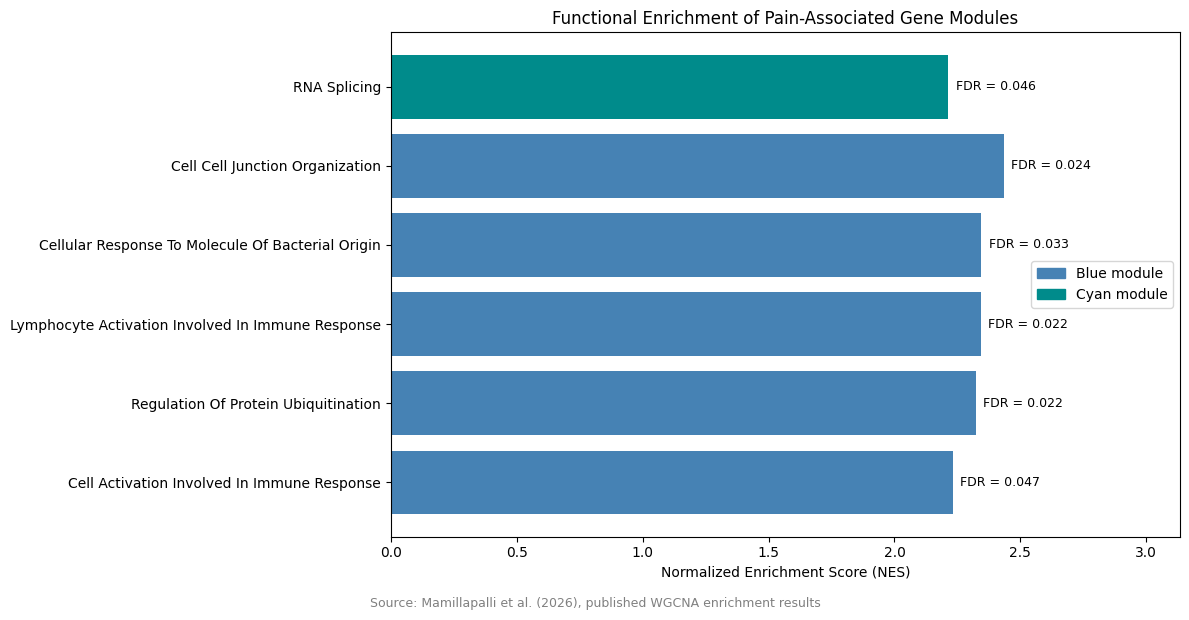

In [25]:

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

plot_data = module_enrichment[
    module_enrichment["FDR"] < 0.05
].copy()

plot_data["CleanName"] = (
    plot_data["GeneSet"]
    .str.replace(r"^(GOBP_|GOMF_|GOCC_)", "", regex=True)
    .str.replace("_", " ")
    .str.title()
    .str.replace("Rna", "RNA", regex=False)
)

plot_data = plot_data.sort_values(["Module", "NES"])

colors = plot_data["Module"].map({
    "blue": "steelblue",
    "cyan": "darkcyan"
})

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.barh(
    plot_data["CleanName"],
    plot_data["NES"],
    color=colors
)

for bar, fdr in zip(bars, plot_data["FDR"]):
    ax.text(
        bar.get_width() + 0.03,
        bar.get_y() + bar.get_height()/2,
        f"FDR = {fdr:.3f}",
        va="center",
        fontsize=9
    )

ax.set_xlabel("Normalized Enrichment Score (NES)")
ax.set_title("Functional Enrichment of Pain-Associated Gene Modules")
ax.set_xlim(0, plot_data["NES"].max() + 0.7)

ax.legend(handles=[
    Patch(color="steelblue", label="Blue module"),
    Patch(color="darkcyan", label="Cyan module")
])

plt.figtext(
    0.5, -0.02,
    "Source: Mamillapalli et al. (2026), published WGCNA enrichment results",
    ha="center",
    fontsize=9,
    color="gray"
)

plt.tight_layout()
plt.savefig("module_enrichment.png", dpi=300, bbox_inches="tight")
plt.show()


## 7. Integrated interpretation

- Published differential-expression results include significant differences in selected inflammation-associated genes, including IL16, RELT, IL17RA, JAK3, and SMPD3.
- Published overall GSEA results include significant gene sets involving hormone activity and neuropeptide receptor binding.
- Applying BH correction to 40 published WGCNA module–pain p-values leaves **three modules** significant at adjusted p < 0.05: blue, cyan, and sienna3. Though each does so narrowly (adjusted p ≈ 0.0496), so these associations should be treated as suggestive rather than definitive.
- In the **published** module enrichment table, the blue module includes immune-related functions, while the cyan module includes RNA splicing.

These analyses point to biologically interesting associations but do **not** prove causation or establish that any individual differential-expression gene belongs to a particular WGCNA module.

## 8. Limitations and conclusions

**Limitations:** 27 samples from only 19 patients; some patients contributed multiple biopsies; possible age, hormonal-status, and technical confounding; summary-level data only; no independent read processing or model fitting; and no supplied per-gene WGCNA module membership table. Enrichment results in Table 6 are a selected published summary rather than a complete independent pathway analysis.

**Conclusion:** Exploratory reanalysis of published endometriosis RNA-seq summary results identifies gene-level differences and enriched biological functions relevant to symptom variability. The independent BH correction highlights three pain-associated WGCNA modules, motivating further validation in larger, patient-independent cohorts.

